# IN4640 Assignment 1 Transformations and Neighborhood  Filtering

1. Implement the intensity transformation depicted in Fig. 1a on the image shown in Fig. 1b, read as a
grayscale image.

(a) Implement the transformation as a 256-entry lookup table (e.g., using cv.LUT or NumPy indexing),
     and show the original and transformed images side by side.


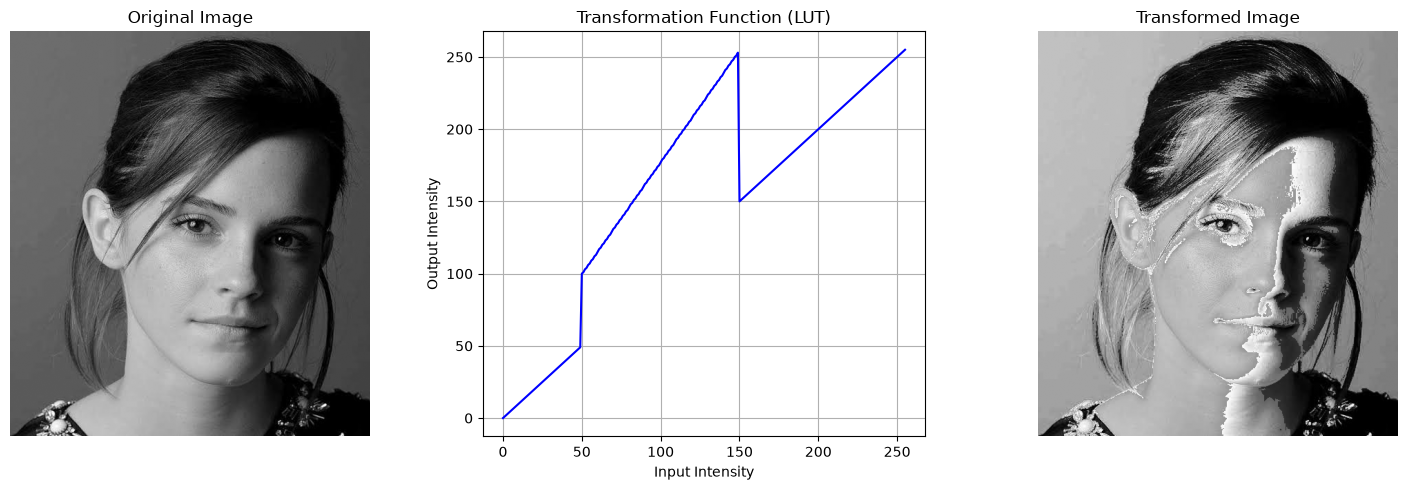

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

img = cv.imread('Images/emma.jpg', cv.IMREAD_GRAYSCALE)


t = np.zeros(256)
t[0:50] = np.arange(0, 50)
t[150:256] = np.arange(150, 256)
t[50:150] = 1.55 * np.arange(50, 150) + 22.5
t = np.clip(t, 0, 255).astype(np.uint8)


img_transformed = cv.LUT(img, t)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].plot(t, color='blue')
axes[1].set_title('Transformation Function (LUT)')
axes[1].set_xlabel('Input Intensity')
axes[1].set_ylabel('Output Intensity')
axes[1].grid(True)

axes[2].imshow(img_transformed, cmap='gray')
axes[2].set_title('Transformed Image')
axes[2].axis('off')

plt.tight_layout()
plt.show()

(b) Explain the visual effect of the transformation. In particular, what happens to pixels with intensities just below and just above 50 and 150?
<br>
<span style="color: blue;"> 
Increases the brightness and contrast of pixels with intensities between 50 and 150.
Pixels below 50 and at or above 150 remain unchanged.
 </span>

## Question 2 – Intensity Transformation for Brain Tissue Enhancement

Apply an intensity transformation similar to Question 1 to accentuate the following tissues in the brain Proton Density (PD) image shown in **Figure 2**:

**(a)** White matter

**(b)** Gray matter

1. Apply a suitable intensity transformation to enhance white matter.
2. Apply a suitable intensity transformation to enhance gray matter.
3. Plot the intensity transformation functions for both cases.
4. Display the resulting enhanced images.
5. State the intensity ranges selected for each tissue and explain how you chose those ranges.



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..246.5].


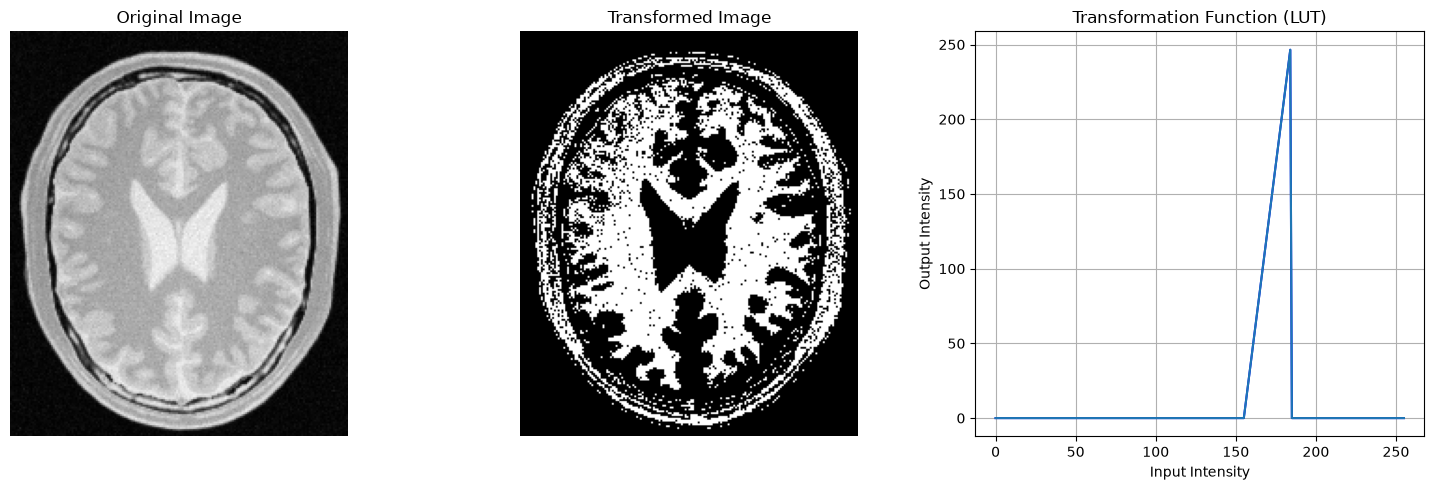

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

im = cv.imread("Images/brain.png")

t = np.zeros(256)
t[155:185] = 255/30 * np.arange(155, 185) - 255/30*155

g = t[im]

# plot the original image and the transformed image and transformtion function
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(im, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(g, cmap='gray')
axes[1].set_title('Transformed Image')
axes[1].axis('off')

axes[2].plot(t, color='blue')
axes[2].set_title('Transformation Function (LUT)')
axes[2].set_xlabel('Input Intensity')
axes[2].set_ylabel('Output Intensity')
axes[2].grid(True)

plt.tight_layout()
plt.plot(t)
plt.show()


## Question 3 [10 Marks]

Consider the image shown in Fig. 31.

### (a)
Apply gamma correction to the L plane in the L∗a∗b∗ color space and state the γ value. Normalize the L plane to [0,1] before applying the power law, and leave the a∗ and b∗ planes unchanged.

### (b)
Show the histograms of the L plane of the original and corrected images.

### (c)
Why is the correction applied to the L plane rather than to each of the R, G, and B planes?

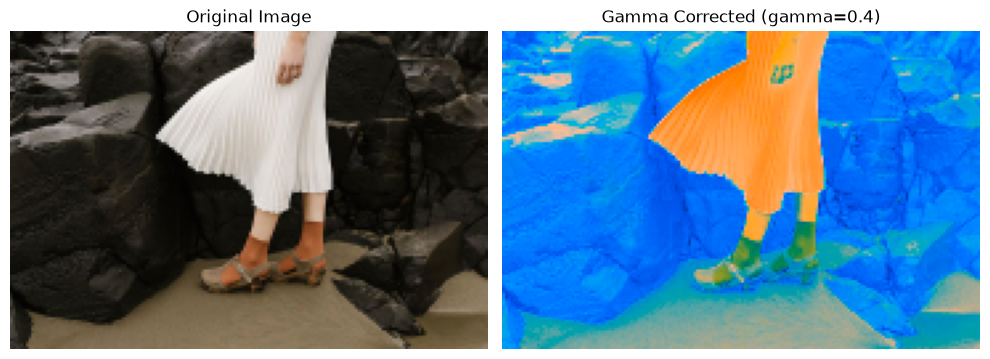

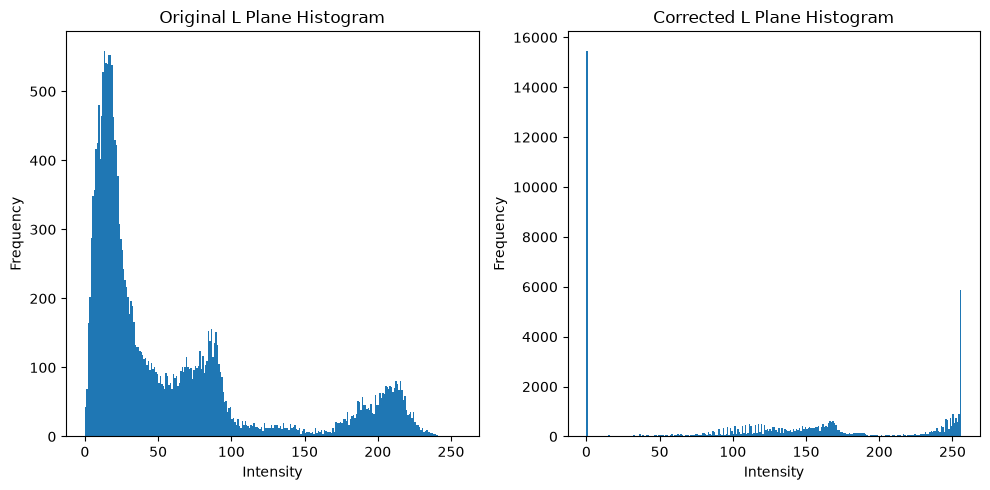

In [22]:
import cv2 as cv
import matplotlib.pyplot as plt

f = cv.imread("Images/highlights_and_shadows.jpg", cv.COLOR_BGR2LAB) # Produce channels Light, Green and Blue

L, a, b = cv.split(f)

# normalize the L plane
L_norm = cv.normalize(L, None, 0, 1, cv.NORM_MINMAX, dtype=cv.CV_32F)

# gamma correction of the L plane
gamma = 0.4
L_powered = np.power(L_norm, gamma)

#Turn pixel values back to 255
L_corrected = np.uint8(L_powered * 255)

# merge L, a , b
f_corrected = cv.merge((L_corrected, a, b))

# cvt color format batck to BGR
corrected_f = cv.cvtColor(f_corrected, cv.COLOR_LAB2BGR)

# Display original and corrected images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(f, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(corrected_f, cv.COLOR_BGR2RGB))
plt.title(f'Gamma Corrected (gamma={gamma})')
plt.axis('off')

plt.tight_layout()
plt.show()

# Display histograms of original and corrected L planes
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.hist(L.ravel(), bins=256, range=(0, 256))
plt.title('Original L Plane Histogram')
plt.xlabel('Intensity')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(corrected_f.ravel(), bins=256, range=(0, 256))
plt.title('Corrected L Plane Histogram')
plt.xlabel('Intensity')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()
 


<ul> <li>The L plane represents lightness. Since we need to make show dark spots of the image using the gamma correction Gamma correction need to apply to Light plane.</li></ul> 

## 4. Vibrance Enhancement Using Saturation Transformation [10 Marks]

Increasing the vibrance of a photograph can be achieved by applying an intensity transformation to the saturation plane, defined as:

\[
f(x)=\min\left(x+a\times128e^{-\frac{(x-128)^2}{2\sigma^2}},\ 255\right)
\]

where:

- \(x \in [0,255]\) is the input intensity.
- \(a \in [0,1]\) is the adjustment parameter.
- \(\sigma = 70\).

### Tasks

**(a)** Split the image shown in Fig. 4 into Hue, Saturation, and Value planes.

**(b)** Apply the aforementioned intensity transformation to the saturation plane.

**(c)** Adjust \(a\) to obtain a visually pleasing output. Report the selected value of \(a\).

**(d)** Recombine the three planes to obtain the vibrance-enhanced image.

**(e)** Display the following:

- Original image.
- Vibrance-enhanced image.
- Intensity transformation curve.

**(f)** Explain how this transformation differs from multiplying the saturation values by a constant factor. Consider pixels with low, medium, and high saturation values in your explanation.

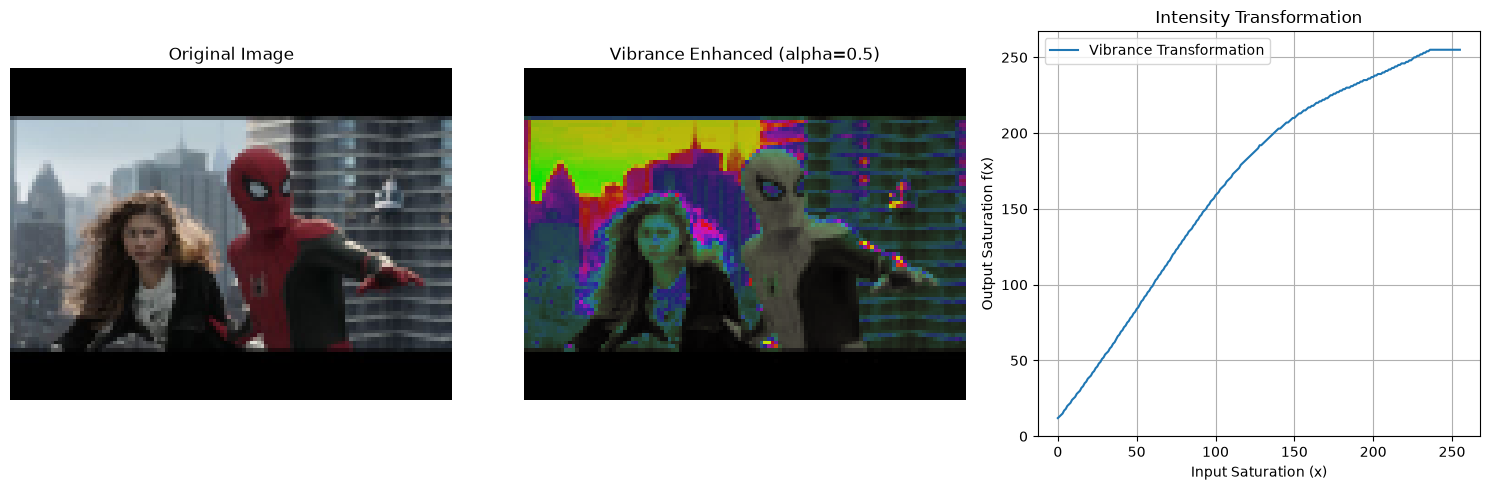

Selected a value: 0.5


In [10]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Convert imge to HSV color format
img = cv.imread('Images/spider-man.jpg', cv.COLOR_BGR2HSV)

# Split img to H, S, V
h, s, v =  cv.split(img)

sigma = 70
alpha = 0.5



# Transformation function
x = np.arange(256)
f = np.minimum(
    x + alpha * 128 * np.exp(-((x - 128) ** 2) / (2 * sigma ** 2)),
    255
).astype(np.uint8)

# Apply transformation function
s_applied = cv.LUT(s, f.astype(np.uint8))

# recombine HSV planes
img_combined = cv.merge([h, s_applied, v])

# Convert back to BGR
final_img = cv.cvtColor(img_combined, cv.COLOR_HSV2BGR)


plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Vibrance enhanced image
plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(final_img, cv.COLOR_BGR2RGB))
plt.title(f"Vibrance Enhanced (alpha={alpha})")
plt.axis("off")

# Transformation curve
plt.subplot(1, 3, 3)
plt.plot(x, f, label="Vibrance Transformation")
plt.xlabel("Input Saturation (x)")
plt.ylabel("Output Saturation f(x)")
plt.title("Intensity Transformation")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


print("Selected a value:", alpha)



# Question: Global and Adaptive Histogram Equalization

In this question, we compare **global histogram equalization** and **adaptive histogram equalization** on the low-contrast image shown in Fig. 5 (`shells.tif`).

**[10 Marks]**

### (a) Implement Global Histogram Equalization

Write your own function to perform histogram equalization using the formulas provided in the lecture slides.

- Implement the histogram equalization algorithm from scratch.
- You may use `cv.equalizeHist()` only to compare your implementation with OpenCV's result.

### (b) Apply CLAHE

Apply **Contrast-Limited Adaptive Histogram Equalization (CLAHE)** using `cv.createCLAHE()` with the following configurations:

- Tile grid size: `8 × 8`
- Clip limit: `2`
- Clip limit: `4`

### (c) Visualize the Results

Display the following images along with their corresponding histograms:

1. Original image (`shells.tif`).
2. Globally equalized image (your implementation).
3. CLAHE image with clip limit = 2.
4. CLAHE image with clip limit = 4.

### (d) Compare and Explain the Results

Compare the four results, paying particular attention to:

- **Background:** Observe how the background appearance and contrast change.
- **Fine details:** Examine how much fine detail and texture on the shells become visible.
- **Global vs. Adaptive:** Explain the differences between global histogram equalization and CLAHE.
- **Clip Limit:** Explain what the clip limit controls and how changing it from 2 to 4 affects contrast enhancement.

Image Shape =  (569, 570)
Image datatype =  uint8


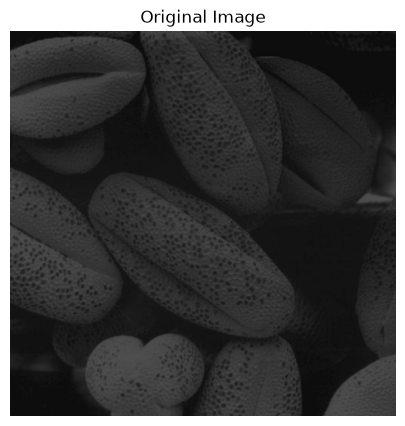

In [7]:
import cv2 as cv
import matplotlib.pyplot as plt



img = cv.imread('Images/shells.jpeg', cv.IMREAD_GRAYSCALE)

print("Image Shape = ", img.shape)
print("Image datatype = ", img.dtype)

plt.figure(figsize=(15, 5))
plt.subplot()
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()


In [5]:
# Implement the Histogram Equalization formula
import numpy as np

def histogram_equalization(img: np.ndarray, L: int = 256) -> np.ndarray:
    hist = np.bincount(img.ravel(), minlength=L)
    N = img.size
    cdf = np.cumsum(hist)
    lookup_table = np.round(((L - 1) / N) * cdf).astype(np.uint8)
    equalized_img = lookup_table[img]
    return equalized_img

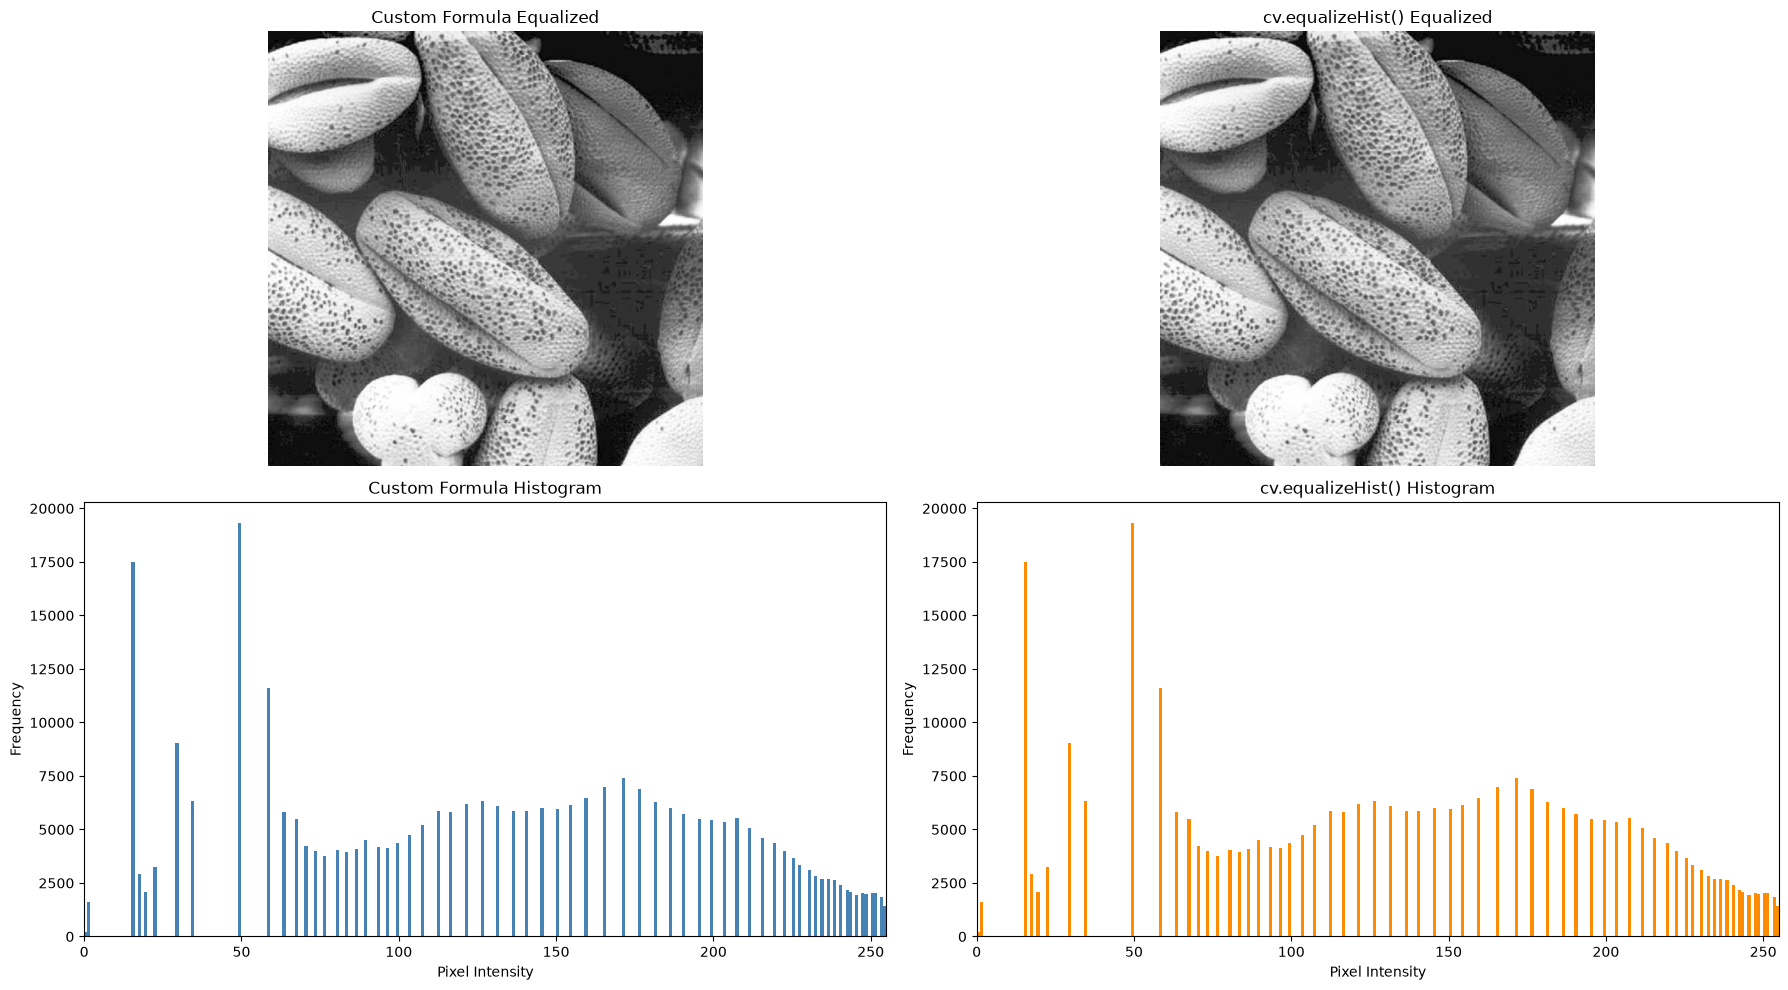

In [12]:
# comparison between developped formula and the cv.equalizeHist()
custom_eq = histogram_equalization(img)
cv_eq = cv.equalizeHist(img)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# Top Row: Images
axes[0, 0].imshow(custom_eq, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Custom Formula Equalized")
axes[0, 0].axis("off")

axes[0, 1].imshow(cv_eq, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("cv.equalizeHist() Equalized")
axes[0, 1].axis("off")


# Bottom Row: Histograms
axes[1, 0].hist(custom_eq.ravel(), bins=256, range=(0, 256), color="steelblue")
axes[1, 0].set_title("Custom Formula Histogram")
axes[1, 0].set_xlabel("Pixel Intensity")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_xlim(0, 255)

axes[1, 1].hist(cv_eq.ravel(), bins=256, range=(0, 256), color="darkorange")
axes[1, 1].set_title("cv.equalizeHist() Histogram")
axes[1, 1].set_xlabel("Pixel Intensity")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_xlim(0, 255)


plt.tight_layout()
plt.show()


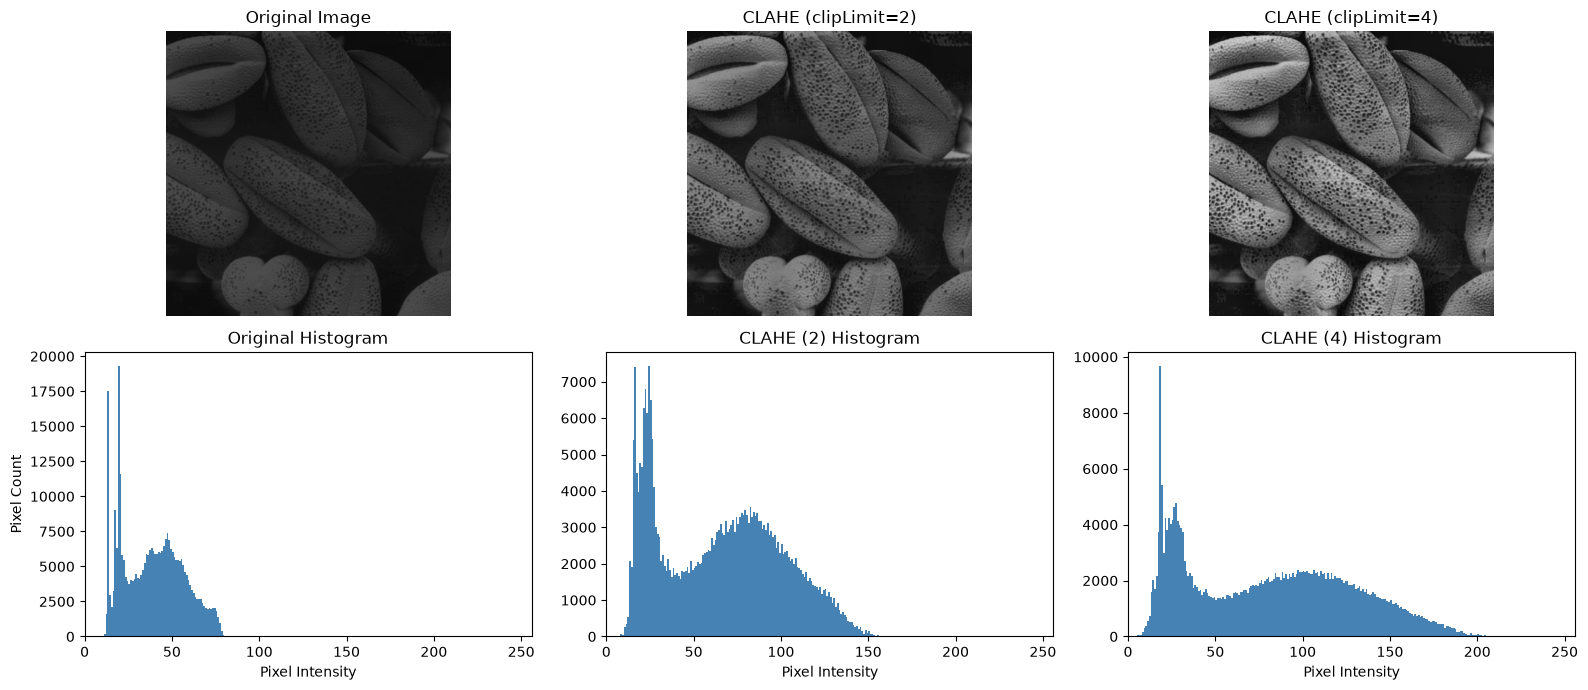

In [16]:
# Apply CLAHE

clahe_2 = cv.createCLAHE(clipLimit=2, tileGridSize=(8,8))
clahe_4 = cv.createCLAHE(clipLimit=4, tileGridSize=(8,8))

applied_clahe_2 = clahe_2.apply(img)
applied_clahe_4 = clahe_4.apply(img)


#  Show the original image, the globally equalized image, and the two CLAHE images, together with their histograms

fig, axes = plt.subplots(2, 3, figsize=(16, 7))

axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[1, 0].hist(img.ravel(), bins=256, range=(0, 256), color='steelblue')
axes[1, 0].set_title('Original Histogram')
axes[1, 0].set_xlabel('Pixel Intensity')
axes[1, 0].set_ylabel('Pixel Count')
axes[1, 0].set_xlim(0, 256)

axes[0, 1].imshow(applied_clahe_2, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title('CLAHE (clipLimit=2)')
axes[0, 1].axis('off')

axes[1, 1].hist(applied_clahe_2.ravel(), bins=256, range=(0, 256), color='steelblue')
axes[1, 1].set_title('CLAHE (2) Histogram')
axes[1, 1].set_xlabel('Pixel Intensity')
axes[1, 1].set_xlim(0, 256)

axes[0, 2].imshow(applied_clahe_4, cmap='gray', vmin=0, vmax=255)
axes[0, 2].set_title('CLAHE (clipLimit=4)')
axes[0, 2].axis('off')

axes[1, 2].hist(applied_clahe_4.ravel(), bins=256, range=(0, 256), color='steelblue')
axes[1, 2].set_title('CLAHE (4) Histogram')
axes[1, 2].set_xlabel('Pixel Intensity')
axes[1, 2].set_xlim(0, 256)

plt.tight_layout()
plt.show()